# Краткое введение в броуновское движение и диффузию


## Вступление

В 1827 году шотландский ботаник по имени Роберт Броун провел серию наблюдений за зернами пыльцы под микроскопом [1]. Пылинки были погружены в воду, и он обнаружил, что их движение носит довольно беспорядочный характер, однако он не смог придумать теорию, которая могла бы объяснить эти наблюдения. Сегодня мы знаем, что это случайное движение вызвано огромным количеством столкновений между пылинками и молекулами воды, и это явление называется "броуновским движением" в честь Роберта Броуна. Первым человеком, который предложил надлежащую теоретическую трактовку броуновского движения, был Альберт Эйнштейн, который в 1905 году опубликовал статью, содержащую количественную теорию этого явления (*Über die von der molekularkinetischen Theorie der Wärme geforderte Bewegung von in ruhenden Flüssigkeiten suspendierten Teilchen*).

## Броуновское движение в одном измерении

Рассмотрим очень простую вероятностную модель случайного движения броуновской частицы, предложенную М. Смолуховским [2]. Тем не менее, эта модель порождает некоторые интересные физические явления, которые мы скоро обнаружим. Временная эволюция положения частицы принимает форму дискретных шагов, и на каждом шаге существует равная вероятность того, что частица переместится на расстояние $h$ влево или на расстояние $h$ вправо. Общее количество предпринятых шагов обозначается как $N = N_l + N_r$, где $N_l$ - количество шагов влево, а $N_r$ - количество шагов вправо. Таким образом, вероятность того, что частица перемещается на n шагов вправо, определяется биномиальным распределением

\begin{align*}
\mathrm{P}_N(N_r = n) &= \binom{N}{n} \left(\frac{1}{2}\right)^n \left(1 - \frac{1}{2}\right)^{N-n} \\
                 &= \binom{N}{n} \left(\frac{1}{2}\right)^N \quad.
\end{align*}
где $$\binom{N}{n} = C_N^n = \frac{N!}{(N-n)!n!}$$  
Положение частицы после $N$ шагов равно расстоянию, пройденному вправо, минус расстояние, пройденное влево, при условии, что частица изначально расположена на $x = 0$

\begin{align*}
x &= (N_r - N_l)\,h \\
  &= (2N_r - N)\,h \quad,
\end{align*}

где мы использовали, что $N_l = N - N_r$. Давайте построим распределение вероятностей для нескольких различных значений $N$.


In [1]:
#%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import binom

In [2]:
# Установим общие параметры рисунка
newparams = {'font.size': 14, 'lines.linewidth': 1.0, 'figure.figsize': (16, 10),
             'legend.frameon': True}
plt.rcParams.update(newparams)

In [3]:
def calc_pos_distribution(N=10, p=0.5, h=1.0):
    """ Creates an array containing the probabilities associated with each position
        of the particle after a number N steps.
        
        Parameters:
            N: int (non-negative). Number of steps in the time evolution.
            p: float (0 <= p <= 1). The probability that the particle moves one step to the right.
            h: float. The distance the particle moves during each step.
            
        Returns: (xs, ps)
            xs: float array. The possible positions of the particle.
            ps: float array. The probabilities of each possible position of the particle.
    """
    ns = np.arange(0, N+1)
    ps = binom(N, ns) * p**ns * (1 - p)**(N - ns)
    xs = h * (2*ns - N)
    return (xs, ps)

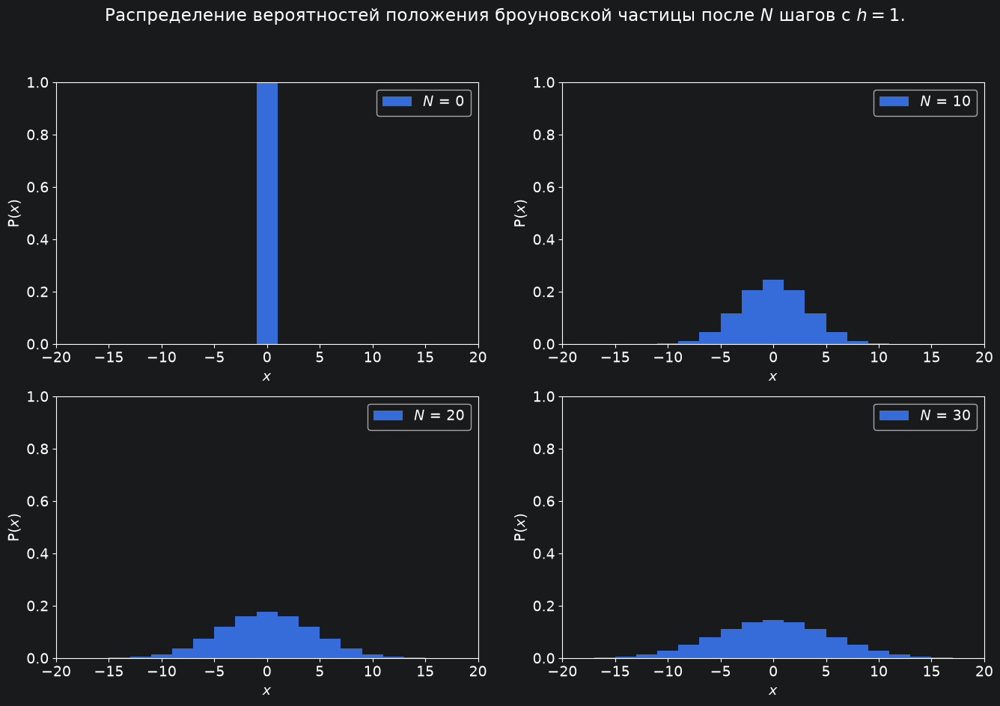

In [4]:
fig = plt.figure()
fig.suptitle("Распределение вероятностей положения броуновской частицы после $N$ шагов с $h = 1$.")

# Handles and data arrays for four subplots
axes        = [None] * 4
pos_arrays  = [None] * 4
prob_arrays = [None] * 4

# Iterate over each subplot
for i in range(0, 4):
    N = 10 * i
    pos_arrays[i], prob_arrays[i] = calc_pos_distribution(N)
    axes[i] = fig.add_subplot(2, 2, i+1)
    axes[i].bar(pos_arrays[i], prob_arrays[i], width=2.0, align='center')
    axes[i].set_ylim([0, 1])
    axes[i].set_xlim([-20, 20])
    axes[i].set_xlabel('$x$')
    axes[i].set_ylabel('P($x$)')
    axes[i].legend(['$N$ = {0}'.format(N)])


Ожидаемое значение положения частицы остается на уровне $x = 0$ для всех $N$, но с течением времени ($N$ растет) распределение вероятностей расползается все больше и больше. Это очень напоминает макроскопическое явление диффузии, когда частицы перемещаются из области высокой концентрации в область более низкой концентрации.
Чтобы увидеть это математически, мы исследуем предел биномиального распределения, где оно приближается к непрерывному распределению вероятностей: пусть $N$ увеличивается, а размер шага $h$ уменьшается таким образом, чтобы $hN$ оставалось постоянным.
Количество шагов $N$ связано со временем $t$ следующим образом: $N = t/\tau$, где $\tau$ - среднее время между столкновениями броуновской частицы и молекулы воды.

В результате получается нормальное распределение, когда $N$ становится большим (вывод приведен в приложении)

\begin{equation*}
\mathrm {P}(x) = \frac{1}{\sqrt{2\pi h^2 t/\tau}} \exp\left({-\frac{1}{2} \frac{x^2}{h^2 t/\tau}}\right).
\end{equation*}

Ожидаемое значение позиции всегда равно $x = 0$, и у нас есть зависящая от времени дисперсия $\sigma^2 = h^2 t/\tau$.
Если мы введем константу $D \equiv h^2/\tau$, нормальное распределение можно записать в следующем виде

\begin{equation*}
\mathrm{P}(x) = \frac{1}{\sqrt{4\pi Dt}} \exp\left({-\frac{1}{2} \frac{x^2}{2Dt}}\right).
\end{equation*}

Предположим, что у нас есть макроскопическая система $\mathcal{N}$ независимых частиц.
Затем концентрацию частиц можно записать в виде

\begin{equation*}
n(x, t) = \mathcal{N} \, \mathrm{P}(x).
\end{equation*}

Прямой расчет показывает, что $n(x, t)$ удовлетворяет одномерному уравнению диффузии

\begin{equation*}
\frac{\partial}{\partial t} n(x, t) = D \frac{\partial^2}{\partial x^2} n(x, t),
\end{equation*}

следовательно, наша простая микроскопическая модель порождает макроскопическое явление диффузии!

## Численное моделирование броуновского движения

Для дальнейшего признания связи между броуновским движением и диффузией было бы полезно визуализировать развитие во времени системы независимых броуновских частиц. Под независимым мы подразумеваем, что движение броуновской частицы не влияет на движение других. Предположим, у нас есть набор $\mathcal{N}$ броуновских частиц, которые могут двигаться в двух измерениях, как описано в приведенной выше модели. Мы собираемся построить график положения частиц после каждого временного шага и действительно наблюдать, что они имеют тенденцию перемещаться из областей с высокой концентрацией в области с более низкой концентрацией.

Во время моделирования мы также собираемся вычислить и отобразить среднее арифметическое и выборочную дисперсию позиций

\begin{align*}
\overline{x} &= \frac{1}{\mathcal{N}} \sum_{k = 1}^\mathcal{N} x_k \\
s_x^2 &= \frac{1}{\mathcal{N}} \sum_{k = 1}^\mathcal{N} (x_k - \overline{x})^2 \quad .
\end{align*}

Ожидаемыми значениями этих величин являются

\begin{align*}
\langle\overline{x}\rangle &= \frac{1}{\mathcal{N}} \sum_{k = 1}^\mathcal{N} \langle x_k \rangle \\
                           &= 0 \\
\langle s_x^2 \rangle &= \frac{1}{\mathcal{N}} \sum_{k = 1}^\mathcal{N} \langle(x_k - \overline{x})^2 \rangle \\
                             &= \frac{1}{\mathcal{N}} \sum_{k = 1}^\mathcal{N} \left(\langle x_k^2 \rangle - \langle \overline{x}\rangle^2\right) \\
                             &= \frac{1}{\mathcal{N}} \sum_{k = 1}^\mathcal{N} \langle x_k^2 \rangle \\
                             &= \frac{1}{\mathcal{N}} \sum_{k = 1}^\mathcal{N} h^2 N \\
                             &= h^2 N \quad .
\end{align*}

In [5]:
from matplotlib import animation
from IPython.display import HTML
plt.rcParams.update({'animation.html':'html5', 'savefig.dpi': 60})

In [6]:
def populate_particles(nParticles, R=0):
    """ Creates two arrays containing randomised positions of the particles.
        The positions are randomised within a circle of radius R about the origin.
        
        Parameters:
            nParticles: int (positive). The number of Brownian particles.
            R: float (positive). The radius within which the randomised positions are confined.
                    
        Returns: (xs, ys)
            xs: float array. The x-coordinates of the particles.
            ys: float array. The y-coordinates of the particles.
    """
    angles = 2*np.pi*np.random.rand(nParticles)
    radii = R*np.random.rand(nParticles)
    xs = radii*np.cos(angles)
    ys = radii*np.sin(angles)
    return (xs, ys)

def evolve_particles(xs, ys, h=0.1, pr=0.5, pu=0.5, vx=0, vy=0):
    """ Evolves the positions of the particles by one time step.
    
        Parameters:
            xs: float array. The x-coordinates of the particles.
            ys: float array. The y-coordinates of the particles.
            h: float. The distance a particle moves during a time step.
            pr: unsigned int (0 <= pr <= 1). The probability that a particle moves to the right along the x-axis.
            pu: unsigned int (0 <= pr <= 1). The probability that a particle moves upwards along the y-axis.
            vx: float. The x-component of the average drift velocity (length h per unit time).
            vy: float. The y-component of the average drift velocity (length h per unit time).
            
        Returns: None. The updated positions are stored in xs and ys.
    """
    if xs.size != ys.size:
        print("Error: The sizes of xs and ys do not match.")
        return -1

    randnumbers = np.random.random(xs.size)
    for i, step_right in enumerate(randnumbers < pr):
        if step_right:
            xs[i] += h
        else:
            xs[i] -= h

    randnumbers = np.random.random(ys.size)
    for i, step_up in enumerate(randnumbers < pu):
        if step_up:
            ys[i] += h
        else:
            ys[i] -= h
            
    # Particle drift
    xs += vx*h
    ys += vy*h
            
def init_anim():
    """ Initialises the animation.
    """
    global ax, line, textbox_sim, textbox_theory
    line, = ax.plot([], [], 'bo')
    ax.set_xlim([-20, 20])
    ax.set_ylim([-20, 20])
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title('Численное моделирование броуновского движения')
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
    # A text box that will display the average and the variance of the positions of the simulated particles.
    textbox_sim = ax.text(0.05, 0.95, '', transform=ax.transAxes, fontsize=12,
                          verticalalignment='top', bbox=props)
    # A text box that will display the average and the variance of the theoretical normal distribution of the positions.
    textbox_theory = ax.text(0.775, 0.95, '', transform=ax.transAxes, fontsize=12,
                             verticalalignment='top', bbox=props)

    return line, textbox_sim, textbox_theory
   

def animate(N, xs, ys, h, nParticles, drift_vx=0, drift_vy=0):
    """ Runs the simulation and updates the plot.
    
        Parameters:
            N: int. The number of time steps taken so far.
            xs: float array. The x-coordinates of the particles.
            ys: float array. The y-coordinates of the particles.
            h: float. The distance a particle moves during a time step.
            nParticles: int (positive). The number of Brownian particles.
            
        Returns: Handles to the objects that are going to be updated in the plot.
    """
    global ax, line, textbox_sim, textbox_theory
    # Evolve the system by one time step.
    evolve_particles(xs, ys, h, vx=drift_vx, vy=drift_vy)
    N += 1
    # Update the plot of the positions.
    line.set_data(xs, ys)

    # Compute and display quantities associated with the simulated particles.
    x_avg, y_avg = np.average(xs), np.average(ys)
    x_var = np.sum((xs - x_avg)**2) / nParticles
    y_var = np.sum((ys - y_avg)**2) / nParticles
    x_avg_str = '$\\langle x \\rangle = %+.2f$' % (x_avg)
    y_avg_str = '$\\langle y \\rangle = %+.2f$' % (y_avg)
    x_var_str = '$\\mathrm{Var}(x) = %.2f$' % (x_var)
    y_var_str = '$\\mathrm{Var}(y) = %.2f$' % (y_var)
    textbox_sim.set_text('Симуляция\n' + x_avg_str + '\n' + y_avg_str + '\n' + x_var_str + '\n' + y_var_str)

    # Compute and display the theoretical quantities.
    x_var = h**2 * N
    y_var = h**2 * N
    x_avg_str = '$\\langle x \\rangle = %.2f$' % (drift_vx * h * N)
    y_avg_str = '$\\langle y \\rangle = %.2f$' % (drift_vy * h * N)
    x_var_str = '$\\mathrm{Var}(x) = %.2f$' % (x_var)
    y_var_str = '$\\mathrm{Var}(y) = %.2f$' % (y_var)
    textbox_theory.set_text('Теория\n' + x_avg_str + '\n' + y_avg_str + '\n' + x_var_str + '\n' + y_var_str)

    return line, textbox_sim, textbox_theory

Следующая ячейка считается долго:

In [7]:
plt.rcParams['animation.embed_limit'] = 80
# Количество броуновских частиц.
nParticles = 500
# Общее количество шагов, предпринятых во время симуляции.
nSteps = 1000
# Создает массивы, содержащие положения x и y частиц.
xs, ys = populate_particles(nParticles)
# Расстояние, которое частицы перемещают во время каждого шага.
h = 0.1

# Запускает симуляцию и визуализирует систему как анимацию.
fig, ax = plt.subplots(figsize=(8, 5), dpi=60)
h_anim = animation.FuncAnimation(fig, animate, init_func=init_anim, frames=nSteps, interval=50,
                                 blit=True, fargs=(xs, ys, h, nParticles))
plt.close(h_anim._fig)
HTML(h_anim.to_jshtml())

## Броуновское движение с дрейфом

До сих пор мы рассматривали систему независимых броуновских частиц, случайно сталкивающихся с окружающими молекулами воды. Таким образом, приведенная выше вероятностная модель учитывает тепловое движение частиц.
Однако мы можем столкнуться с ситуациями, когда необходимо включить другие механизмы в решение нашей системы. Например, броуновские частицы могут быть ионами в растворе, подверженном воздействию внешнего электрического поля, заставляющего частицы дрейфовать в направлении поля. Другим примером может быть, когда мы принимаем во внимание столкновения между самими броуновскими частицами и существует равномерный градиент концентрации по всей системе, что приводит к постоянной скорости дрейфа.

Во-первых, дается вывод более общего выражения для производной по времени концентрации частиц. Это уравнение можно рассматривать как обобщение уравнения диффузии, которое также включает в себя возможность дрейфа частиц. Затем мы возвращаемся к микрофизике и добавляем термин дрейфа частиц в вероятностную модель. Как мы увидим, микроскопическая модель снова согласуется с макроскопической моделью – на этот раз описываемой уравнением дрейфа-диффузии.

#### Вывод уравнения дрейфа-диффузии

Пусть $\rho(\mathbf{r}, t)$ обозначает плотность частиц. Мы предполагаем, что общее число частиц в системе сохраняется, следовательно, для произвольного объема изменение числа частиц в объеме должно равняться числу частиц, покидающих объем. Математически это можно выразить следующим образом

\begin{equation*}
\int_\mathrm{V} \frac{\partial}{\partial t}\rho(\mathbf{r}, t) \, \mathrm{d}V = - \oint_\mathrm{S} \mathbf{j} \cdot \hat{n}\, \mathrm{d}A,
\end{equation*}

где $\mathbf{j}$ обозначает поток частиц, а правая часть уравнения представляет собой интеграл, взятый по замкнутой поверхности, охватывающей объем $V$. Используя теорему о дивергенции, поверхностный интеграл может быть переписан как

\begin{equation*}
\int_\mathrm{V} \frac{\partial}{\partial t}\rho(\mathbf{r}, t) \, \mathrm{d}V = - \int_\mathrm{V} \nabla\cdot {\mathbf{j}} \, \mathrm{d}V.
\end{equation*}

Поскольку объем предполагался произвольным, подынтегральные выражения должны быть равны, что дает *уравнение непрерывности*

\begin{equation*}
\frac{\partial}{\partial t}\rho(\mathbf{r}, t) + \nabla\cdot \mathbf{j} = 0.
\end{equation*}

Это отправная точка вывода. Мы рассматриваем два механизма, которые вносят вклад в поток частиц:

1. Диффузия, обусловленная тепловым движением частиц.
2. Дрейф частиц.

Первый закон диффузии Фика гласит, что$\, \mathbf{j_\mathrm{diff}} = -D \nabla\rho$,
где фактор $D$ - коэффициент диффузии.
Интуитивный способ мышления об этом законе таков: в областях с более высокой концентрацией частиц скорость столкновения будет выше, чем в областях с более низкой концентрацией. Таким образом, более вероятно, что частицы рассеиваются из областей с более высокой концентрацией в области с более низкой концентрацией, а не в противоположном направлении, что приводит к чистому потоку частиц, пропорциональному $-\nabla\rho$.

Слагаемое дрейфа задается $\, \mathbf{j_\mathrm{drift}} = \rho \mathbf{v}$, где $\mathbf{v}$ - скорость дрейфа частиц. Можно думать об этом как о средней скорости группы частиц.
Таким образом, общий поток частиц можно записать в виде

\begin{align*}
\mathbf{j} &= \mathbf{j_\mathrm{diff}} + \mathbf{j_\mathrm{drift}} \\
           &= -D \nabla\rho + \rho \mathbf{v}.
\end{align*}

Подстановка выражения для потока частиц в уравнение непрерывности дает

\begin{align*}
\frac{\partial}{\partial t}\rho(\mathbf{r}, t) &= - \nabla \cdot \mathbf{j} \\
&= - \nabla\cdot (-D\nabla\rho + \rho\mathbf{v}) \\
&= \nabla\cdot (D\nabla\rho) - \mathbf{v}\cdot \nabla\rho - \rho \nabla\cdot \mathbf{v} \\
&= D\nabla^2\rho - \mathbf{v}\cdot \nabla\rho .
\end{align*}

На последнем шаге мы предположили, что $D$ постоянна и что система несжимаема ($\nabla\cdot \mathbf{v} = 0$).
Таким образом, уравнение дрейфа-диффузии в одном измерении гласит

\begin{equation*}
\frac{\partial}{\partial t}\rho(x, t) = D\frac{\partial^2}{\partial x^2}\rho(x, t) - v_x \frac{\partial}{\partial x}\rho(x, t) .
\end{equation*}

#### Добавление дрейфа в вероятностную модель

Положение броуновской частицы с дрейфом задается $x = (2N_r - N)\,h + v_x t$,
где $v_x$ - скорость дрейфа, а $t$ - параметр времени.
В приложении показано, что для больших $N$ плотность вероятности $x$ приближается к следующему нормальному распределению

\begin{equation*}
\mathrm{p}(x) \approx \frac{1}{\sqrt{4\pi Dt}} \exp\left({-\frac{1}{2} \frac{(x-v_x t)^2}{2Dt}}\right) \quad ,
\end{equation*}

что удовлетворяет уравнению дрейфа-диффузии!

## Численное моделирование броуновского движения с дрейфом

In [8]:
plt.rcParams['animation.embed_limit'] = 80
# Количество броуновских частиц.
nParticles = 500
# Общее количество шагов, предпринятых во время симуляции.
nSteps = 250
# Создает массивы, содержащие положения x и y частиц.
xs, ys = populate_particles(nParticles)
# Расстояние, которое частицы перемещают во время каждого шага.
h = 0.1
# Компоненты средней скорости дрейфа (длина H на единицу времени)
drift_vx = 0.5
drift_vy = 0

# Запускает симуляцию и визуализирует систему как анимацию.
fig, ax = plt.subplots(figsize=(8, 5), dpi=60)
h_anim = animation.FuncAnimation(fig, animate, init_func=init_anim, frames=nSteps, interval=50, blit=True,
                                 fargs=(xs, ys, h, nParticles, drift_vx, drift_vy))
plt.close(h_anim._fig)
HTML(h_anim.to_jshtml())

## Вывод

Мы продемонстрировали, как простая вероятностная модель движения броуновских частиц может быть использована для объяснения того, почему частицы стремятся двигаться в области с более низкой концентрацией. Микроскопическая вероятностная модель с добавленным членом дрейфа согласуется с макроскопическим уравнением дрейфа-диффузии.

## Appendix

### Биномиальное распределение приближается к нормальному распределению, когда $N$ становится большим, а $hN$ остается постоянным.

Сама суть этого вывода состоит в том, чтобы посмотреть на генерирующую моменты функцию биномиально распределенного положения частицы, затем позволить $N$ вырасти и увидеть, что мы в конечном итоге получаем генерирующую момент функцию нормального распределения. Сначала мы изложим несколько общих результатов.

Функция генерирующая моменты случайной величины $X$ определяется

\begin{equation*}
\mathrm{M}_X(k) = \langle e^{kX} \rangle \quad .
\end{equation*}

Для линейного преобразования $aX + b$, где $a$ и $b$ являются константами, мы имеем, что

\begin{equation*}
{\mathrm M}_{aX+b}(k) = e^{-bk} \, {\mathrm M}_X(ak) \quad .
\end{equation*}

#### Теорема о моментообразующих функциях

Предположим, что $X$ и $Y$ - случайные величины, для которых ${\mathrm M}_X(k)$ = ${\mathrm M}_Y(k)$
для некоторого интервала, содержащего $k = 0$. Тогда распределения вероятностей $X$ и $Y$ равны. [3]

#### Моментообразующие функции биномиального распределения и нормального распределения [4]

Для биномиального распределения $n$

\begin{equation*}
\mathrm{P}_N(n) = \binom{N}{n} p^n (1 - p)^{N-n} \quad ,
\end{equation*}

функция, генерирующая момент:

\begin{equation*}
\mathrm{M}_n(k) = (p e^k + 1-p)^N \quad .
\end{equation*}

Для нормального распределения $x$

\begin{equation*}
\mathrm{p}(x) = \frac{1}{\sqrt{2\pi} \sigma} \exp\left(-\frac{1}{2} \frac{(x-\mu)^2}{\sigma^2}\right) \quad ,
\end{equation*}

функция, генерирующая момент, имеет вид

\begin{equation*}
\mathrm{M}_x(k) = e^{\mu k + \sigma^2 k^2 / 2} \quad .
\end{equation*}

#### От биномиального распределения к нормальному распределению

Напомним,что положение броуновской частицы было задано $x = (2N_r - N)\, h$.
С $p = 1/2$ мы имеем, что

\begin{align*}
\mathrm{M}_x(k) &= e^{-hNk} \, {\mathrm M}_{2hN_r}(k) \\
                   &= e^{-hNk} \left( \frac{1}{2} e^{2hk} + \frac{1}{2} \right)^N \\
                   &= e^{-hNk} \left( \frac{1}{2} e^{2hNk/N} + \frac{1}{2} \right)^N \\
                   &= e^{-yk} \left( \frac{1}{2} e^{2yk/N} + \frac{1}{2} \right)^N \quad ,
\end{align*}

где $y \equiv hN$ поддерживается постоянным. По мере того, как $N$ становится большим, мы делаем следующее приближение

\begin{equation*}
e^{2yk/N} \approx 1 + \frac{2yk}{N} + \left(\frac{yk}{N}\right)^2 \quad ,
\end{equation*}

что подразумевает, что

\begin{equation*}
\mathrm{M}_x(k) \approx e^{-yk} \left( 1 + \frac{yk + y^2 k^2 / 2N}{N} \right)^N \quad .
\end{equation*}

Мы также используем другое приближение

\begin{equation*}
\left( 1 + \frac{u}{N} \right)^N \approx e^u \quad ,
\end{equation*}

который действителен, когда $\frac{u}{N} \ll 1$, следовательно, для больших $N$

\begin{align*}
\mathrm{M}_x(k) &\approx e^{-yk} e^{yk + y^2 k^2 / 2N} \\
                   &= e^{(y^2/N) k^2 / 2} \quad .
\end{align*}

Это мы сразу распознаем как производящую момент функцию $x$ для нормального распределения с $\mu = 0$ и
$\sigma^2 = y^2/N$. Область этой функции, генерирующей момент, содержит $k = 0$, следовательно, по мере того, как $N$ становится большим, а $hN$ остается постоянным

\begin{align*}
\mathrm{p}(x) &\approx \frac{1}{\sqrt{2\pi y^2/N}} \exp\left(-\frac{1}{2} \frac{x^2}{y^2/N}\right) \\
               &= \frac{1}{\sqrt{2\pi h^2 t/\tau}} \exp\left(-\frac{1}{2} \frac{x^2}{h^2 t/\tau}\right) \\
               &= \frac{1}{\sqrt{4\pi Dt}} \exp\left({-\frac{1}{2} \frac{x^2}{2Dt}}\right) \quad .
\end{align*}

Альтернативный и более прямой подход с использованием приближения Стирлинга можно найти в [5].

#### Добавление слагаемого с дрейфом

Теперь мы рассмотрим броуновское движение с дрейфом.
Положение броуновской частицы задается $\tilde{x} = (2N_r - N)\,h + v_x t$,
где $v_x$ - скорость дрейфа, а $t = N\tau$ - параметр времени.
Слагаемое $v_x t$ является константой (а не случайной величиной), следовательно, генерирующая момент функция  по $\tilde{x}$ становится

\begin{equation*}
\mathrm{M}_\tilde{x}(k) = e^{-v_x tk} \, {\mathrm M}_{(2N_r-N)h}(k) \quad.
\end{equation*}

Используя наш предыдущий результат для ${\mathrm M}_{(2N_r-N)h}(k)$ для больших значений $N$ 

\begin{equation*}
\mathrm{M}_\tilde{x}(k) \approx e^{-v_x tk + (y^2/N) k^2 / 2} \quad ,
\end{equation*}

который мы признаем производящей момент функцией $x$ для нормального распределения с $\mu = v_x t$ и $\sigma^2 = y^2/N$.

Плотность вероятности положения броуновской частицы с дрейфом, таким образом, равна

\begin{equation*}
\mathrm{p}(x) \approx \frac{1}{\sqrt{4\pi Dt}} \exp\left({-\frac{1}{2} \frac{(x-v_x t)^2}{2Dt}}\right) \quad .
\end{equation*}

## References

[1] R. Brown, "A brief account of microscopical observations made in the months of June, July and August, 1827, on the particles contained in the pollen of  plants; and on the general existence of active molecules in organic and inorganic bodies", *The miscellaneous botanical works of Robert Brown*, (The Ray Society, London, 1866), pp. 463. Available: [The miscellaneous botanical works of Robert Brown](https://archive.org/details/miscellaneousbot01brow) \[11.09.2016\].

[2] M. Smoluchowski, "Zur kinetischen Theorie der Brownschen Molekularbewegung und der Suspensionen", *Annalen der Physik* **21** (14), pp. 756 (1906).

[3] R. J. Larsen & M. L. Marx, *An introduction to Mathematical Statistics and Its Applications*, 5th Edition, 2012, Pearson, p. 214.

[4] Institutt for matematiske fag NTNU, *Tabeller og formler i statistikk*, 6. opplag, 2011, Fagbokforlaget, s. 25.

[5] R. K. Pathria & P. D. Beale, *Statistical Mechanics*, 3rd Edition, 2011, Butterworth–Heinemann, p. 588.